# Pretrained full-data models

Load two archived 20,000-step full-data gastrulation networks from the public COATI
repository and run inference without refitting. These are not the strict leave-one-stage-out
models used for the held-out benchmark.

Both models use $C_y=0.3$ and RNA50. Their architectures and loss coefficients differ, so
this notebook inspects the two fitted models rather than treating balance as the only changed
parameter.

In [1]:
from pathlib import Path
import sys

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
example_dir = project_dir / "examples" if project_dir is not None else Path.cwd()
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from gastrulation_pretrained import (
    load_gastrulation_result,
    load_gastrulation_umap,
    obtain_gastrulation_assets,
)

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

## Obtain the public assets

Inside a COATI checkout the committed files are used directly. Outside the repository,
the same helper downloads them from the corresponding raw GitHub directory and verifies
their SHA-256 checksums.

In [2]:
assets, manifest = obtain_gastrulation_assets()
model_files = [
    "balanced_cy0p3_s1_iter20000.pth",
    "unbalanced_cy0p3_s0_iter20000.pth",
]
rows = []
for name in model_files:
    spec = manifest["assets"][name]
    rows.append({
        "Model": "Unbalanced" if spec["unbalanced"] else "Balanced",
        "Seed": spec["seed"], "Cy": spec["cy"], "Iterations": spec["iteration"],
        "Energy": spec["energy_coefficient"], "Density": spec["density_coefficient"],
        "PDF": spec["pdf_coefficient"], "Width": spec["hidden_dim"],
        "Layers": spec["n_layers"],
    })
pd.DataFrame(rows).set_index("Model")

,Seed,Cy,Iterations,Energy,Density,PDF,Width,Layers
Model,,,,,,,,
Balanced,1,0.3,20000,0.10,0.10,100.0,400,4
Unbalanced,0,0.3,20000,0.01,0.01,100.0,800,3


## Load the networks

The compatibility loader reconstructs each exact architecture from the manifest, checks
the stored iteration and returns a COATI `Result`. Both networks are evaluated from the
same 600 E7.5 cells on the original 0.1 integration grid.

In [3]:
data_path = assets["rna_pca_by_time.npz"]
balanced = load_gastrulation_result(
    assets["balanced_cy0p3_s1_iter20000.pth"], data_path, manifest=manifest,
)
unbalanced = load_gastrulation_result(
    assets["unbalanced_cy0p3_s0_iter20000.pth"], data_path, manifest=manifest,
)

rng = np.random.default_rng(7)
initial_index = np.sort(rng.choice(len(balanced.data.primary[0]), 600, replace=False))
initial = balanced.data.primary[0][initial_index]
integration_times = np.linspace(0.0, 2.5, 26)
predictions = {
    "Balanced": balanced.predict_trajectory(initial, times=integration_times),
    "Unbalanced": unbalanced.predict_trajectory(initial, times=integration_times),
}
assert predictions["Balanced"]["primary"].shape == (26, 600, 50)
assert predictions["Unbalanced"]["primary"].shape == (26, 600, 50)
assert np.isfinite(predictions["Balanced"]["primary"]).all()
assert np.isfinite(predictions["Unbalanced"]["primary"]).all()
print("Loaded iterations:", balanced.metadata["checkpoint_iteration"], unbalanced.metadata["checkpoint_iteration"])
print("Unbalanced final mass ratio:", f"{np.exp(predictions['Unbalanced']['log_weights'][-1]).sum():.3f}")

Loaded iterations: 20000 20000
Unbalanced final mass ratio: 10.799


## Two UMAP views

Load the original RNA UMAP model instead of fitting a new embedding. Its 35,503 fitting
rows are exactly the concatenated RNA50 snapshots in `rna_pca_by_time.npz`; the loader
checks both values and order. The gray atlas uses the reducer's saved `embedding_`.

Only the predicted distributions at the four observed stages are shown. No trajectory
lines are drawn.

In [4]:
umap_model = load_gastrulation_umap(assets["rna_umap_model.joblib"], data_path)
reference_umap = np.asarray(umap_model.embedding_)
stage_names = ["E7.5", "E8.0", "E8.5", "E8.75"]
stage_colors = ["#355F8D", "#2A9D8F", "#E9C46A", "#E76F51"]
stage_steps = [0, 10, 20, 25]
snapshot_umap = {
    name: umap_model.transform(prediction["primary"][stage_steps].reshape(-1, 50)).reshape(4, 600, 2)
    for name, prediction in predictions.items()
}

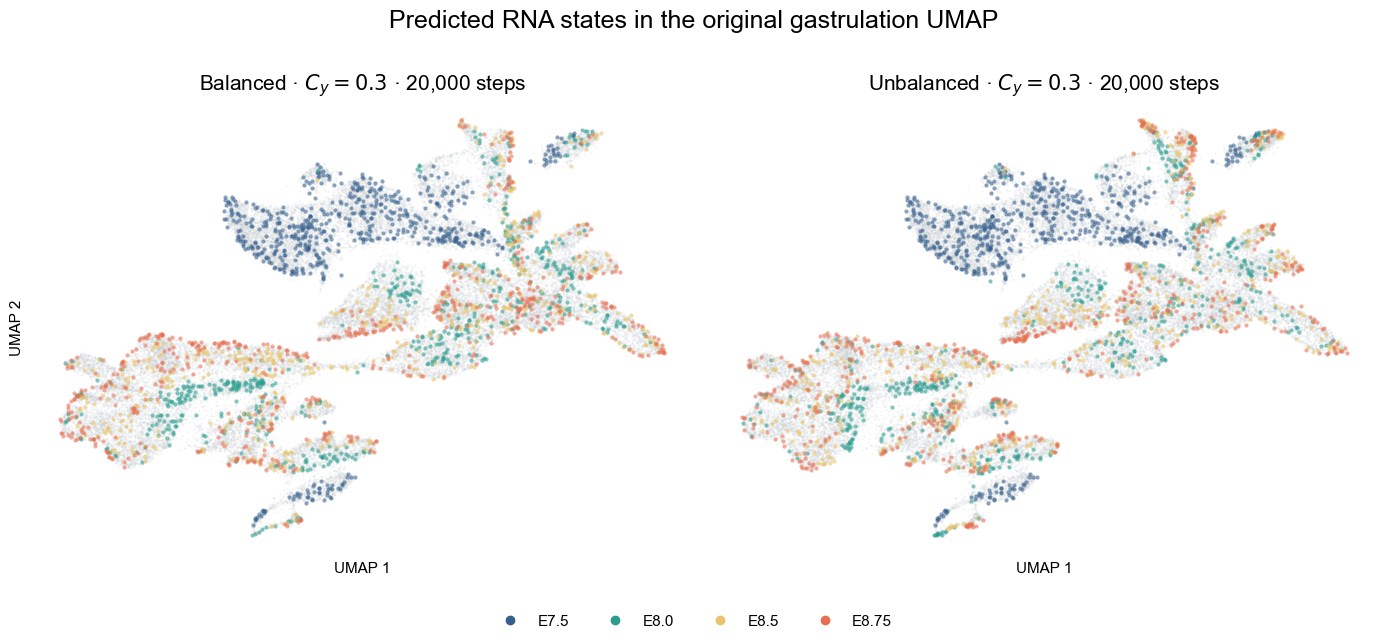

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["Balanced", "Unbalanced"]):
    ax.scatter(reference_umap[:, 0], reference_umap[:, 1], s=2.2,
               color="#C8CDD2", alpha=.24, linewidths=0, rasterized=True)
    for stage, color, points in zip(stage_names, stage_colors, snapshot_umap[name]):
        ax.scatter(points[:, 0], points[:, 1], s=9, color=color, alpha=.58,
                   linewidths=0, rasterized=True, label=stage)
    ax.set_title(f"{name} · $C_y=0.3$ · 20,000 steps", fontsize=15)
    ax.set_xlabel("UMAP 1")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("UMAP 2")
stage_handles = [Line2D([0], [0], marker="o", linestyle="", color=color,
                        label=stage, markersize=6)
                 for stage, color in zip(stage_names, stage_colors)]
fig.legend(handles=stage_handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(.5, -.01))
fig.suptitle("Predicted RNA states in the original gastrulation UMAP", fontsize=18, y=1.01)
fig.tight_layout(rect=(0, .07, 1, 1))
plt.show()

The panels directly inspect the two archived full-data checkpoints. They are not
a controlled balanced-versus-unbalanced ablation because the networks also differ in seed,
width, depth and loss coefficients.